# Step 6 — Post-load preprocessing, EDA, and analytical modeling

This notebook loads the raw relational CSV files, performs post-load quality checks, explores the delivered-order subset, and creates descriptive RFM, cohort, delivery, and transaction-level CLV extracts.

Important rules: `customer_unique_id` identifies a person across orders; delivered orders are used for realized-sales analysis; item revenue, freight, and payment totals remain separate; amounts are in BRL; this is a repeat-customer-prioritized subset and is not representative of the full Olist population.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\mukth\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 1. Load CSV files

The relative paths match the existing pre-analysis notebook convention.

In [2]:
# Load csv files

orders = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_orders_dataset.csv')
customers = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_customers_dataset.csv')
items = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_items_dataset.csv')
payments = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_reviews_dataset.csv')
products = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_products_dataset.csv')
sellers = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_sellers_dataset.csv')
categories = pd.read_csv('../data/raw/olist_trimmed_1500_relational/product_category_name_translation.csv')
geolocation = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_geolocation_dataset.csv')

In [3]:
# Store all loaded tables in one dictionary for repeatable checks.
tables = {'orders': orders, 'customers': customers, 'items': items, 'payments': payments,
          'reviews': reviews, 'products': products, 'sellers': sellers,
          'categories': categories, 'geolocation': geolocation}

table_summary = pd.DataFrame({
    'table': list(tables.keys()),
    'rows': [df.shape[0] for df in tables.values()],
    'columns': [df.shape[1] for df in tables.values()]
})
table_summary

,table,rows,columns
0,orders,1208,8
1,customers,1208,5
2,items,1500,7
3,payments,1303,5
4,reviews,1298,7
5,products,1096,9
6,sellers,494,4
7,categories,57,2
8,geolocation,956,5


## 2. Post-load preprocessing and quality checks

In [4]:
# Convert timestamp columns to datetime so date arithmetic is reliable.
order_date_columns = [column for column in orders.columns if 'date' in column or 'timestamp' in column]
for column in order_date_columns:
    orders[column] = pd.to_datetime(orders[column], errors='coerce')

orders['order_status'] = orders['order_status'].astype('string').str.strip().str.lower()
customers['customer_unique_id'] = customers['customer_unique_id'].astype('string').str.strip()

# Numeric conversion keeps analysis columns usable even when a source value is missing.
for column in ['price', 'freight_value']:
    items[column] = pd.to_numeric(items[column], errors='coerce')
payments['payment_value'] = pd.to_numeric(payments['payment_value'], errors='coerce')
reviews['review_score'] = pd.to_numeric(reviews['review_score'], errors='coerce')
orders[order_date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [5]:
# Check missing values and duplicate rows in every loaded table.
quality_summary = []
for name, df in tables.items():
    quality_summary.append({
        'table': name,
        'rows': len(df),
        'duplicate_rows': int(df.duplicated().sum()),
        'missing_cells': int(df.isna().sum().sum())
    })
pd.DataFrame(quality_summary)

,table,rows,duplicate_rows,missing_cells
0,orders,1208,0,1
1,customers,1208,0,0
2,items,1500,0,0
3,payments,1303,0,0
4,reviews,1298,0,1974
5,products,1096,0,112
6,sellers,494,0,0
7,categories,57,0,0
8,geolocation,956,0,0


In [6]:
# Keep only delivered orders for realized-sales and retention analysis.
eligible_orders = orders.loc[orders['order_status'].eq('delivered')].copy()

# Check key and relationship coverage before joining tables.
checks = {
    'unique_order_ids': eligible_orders['order_id'].nunique(),
    'duplicate_order_ids': int(eligible_orders['order_id'].duplicated().sum()),
    'orders_without_customers': int((~eligible_orders['customer_id'].isin(customers['customer_id'])).sum()),
    'items_without_orders': int((~items['order_id'].isin(orders['order_id'])).sum()),
    'items_without_products': int((~items['product_id'].isin(products['product_id'])).sum()),
    'items_without_sellers': int((~items['seller_id'].isin(sellers['seller_id'])).sum()),
    'invalid_review_scores': int((~reviews['review_score'].between(1, 5)).sum())
}
pd.Series(checks, name='check_value')

unique_order_ids            1208
duplicate_order_ids            0
orders_without_customers       0
items_without_orders           0
items_without_products         0
items_without_sellers          0
invalid_review_scores          0
Name: check_value, dtype: int64

## 3. Create an order-level analytical table

Items and payments are aggregated separately before joining so one-to-many joins do not multiply totals.

In [7]:
# Aggregate order items to order grain.
item_order_summary = (items.groupby('order_id', as_index=False)
    .agg(item_count=('order_item_id', 'count'), item_revenue=('price', 'sum'),
         freight_collected=('freight_value', 'sum')))

# Aggregate payments to order grain.
payment_order_summary = (payments.groupby('order_id', as_index=False)
    .agg(payment_total=('payment_value', 'sum'), payment_count=('payment_sequential', 'count')))

# Add person-level customer identity and order-level financial measures.
order_fact = (eligible_orders.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left')
    .merge(item_order_summary, on='order_id', how='left')
    .merge(payment_order_summary, on='order_id', how='left'))
order_fact['item_plus_freight'] = order_fact['item_revenue'] + order_fact['freight_collected']
order_fact[['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'item_revenue', 'freight_collected', 'payment_total']].head()

,order_id,customer_unique_id,order_purchase_timestamp,item_revenue,freight_collected,payment_total
0,dcb36b511fcac050b97cd5c05de84dc3,ccafc1c3f270410521c3c6f3b249870f,2018-06-07 19:03:12,132.4,14.05,146.45
1,a685d016c8a26f71a0bb67821070e398,51838d41add414a0b1b989b7d251d9ee,2017-03-13 18:14:36,84.9,14.36,99.26
2,f175d67589e059cbbda956f10f0702e6,f7be9bec658c62ab6240b44cd26c0b84,2017-01-05 13:34:35,9.9,8.72,18.62
3,7e3e92dc3eaf5389f32da97228f7dd0e,ba77e9b6506636dcbd03e463d4786f24,2017-07-02 20:47:24,79.9,15.31,95.21
4,dc400373e624e9b0435847a79813c658,d02cbb85434c84acabb8e81bbf064d3e,2018-01-14 18:49:14,39.9,9.34,49.24


## 4. Exploratory data analysis

In [8]:
# Monthly orders, customers, and revenue.
order_fact['purchase_month'] = order_fact['order_purchase_timestamp'].dt.to_period('M').astype('string')
monthly_sales = (order_fact.groupby('purchase_month', as_index=False)
    .agg(order_count=('order_id', 'nunique'), unique_customers=('customer_unique_id', 'nunique'),
         item_revenue=('item_revenue', 'sum'), freight_collected=('freight_collected', 'sum')))
monthly_sales['item_plus_freight'] = monthly_sales['item_revenue'] + monthly_sales['freight_collected']
monthly_sales.head()

,purchase_month,order_count,unique_customers,item_revenue,freight_collected,item_plus_freight
0,2016-10,23,20,2573.98,416.60,2990.58
1,2016-12,1,1,10.90,8.72,19.62
2,2017-01,93,61,8878.50,1862.18,10740.68
3,2017-02,99,76,10302.07,2301.60,12603.67
4,2017-03,102,76,14171.61,2269.52,16441.13


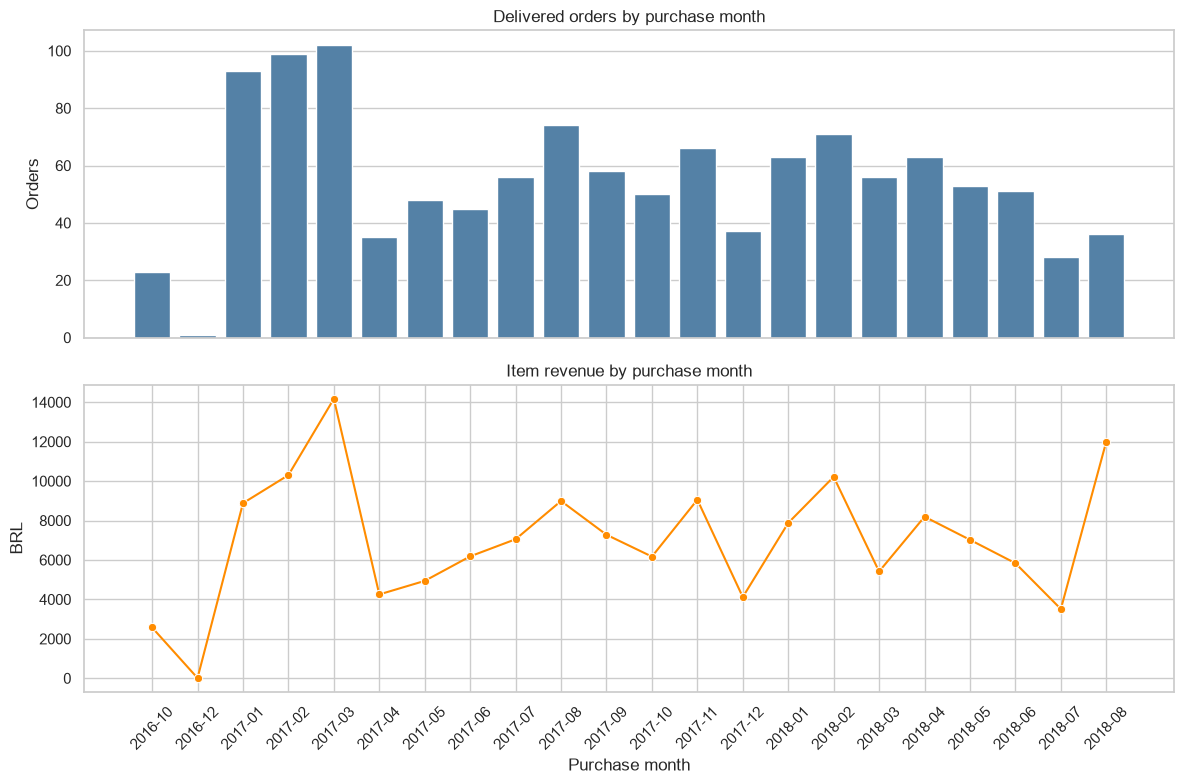

In [9]:
# Plot monthly order volume and item revenue.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.barplot(data=monthly_sales, x='purchase_month', y='order_count', ax=axes[0], color='steelblue')
axes[0].set(title='Delivered orders by purchase month', xlabel='', ylabel='Orders')
sns.lineplot(data=monthly_sales, x='purchase_month', y='item_revenue', marker='o', ax=axes[1], color='darkorange')
axes[1].set(title='Item revenue by purchase month', xlabel='Purchase month', ylabel='BRL')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()

In [10]:
# Translate categories where a translation exists and find top categories.
product_categories = products.merge(categories, on='product_category_name', how='left')
item_categories = items.merge(product_categories[['product_id', 'product_category_name_english']], on='product_id', how='left')
item_categories['category_name'] = item_categories['product_category_name_english'].fillna('unknown')
top_categories = (item_categories.groupby('category_name', as_index=False)
    .agg(item_count=('order_item_id', 'count'), item_revenue=('price', 'sum'))
    .sort_values('item_revenue', ascending=False).head(10))
top_categories

,category_name,item_count,item_revenue
6,bed_bath_table,222,20558.99
51,sports_leisure,133,17386.90
29,furniture_decor,166,12817.62
57,watches_gifts,77,12734.13
10,computers_accessories,102,11459.75
32,health_beauty,105,9767.52
37,housewares,90,7300.88
21,fashion_bags_accessories,70,6654.39
54,telephony,55,4998.24
44,musical_instruments,3,4464.67


## 5. RFM customer analysis

In [11]:
# Calculate descriptive RFM metrics at person level.
observation_cutoff = order_fact['order_purchase_timestamp'].max().normalize()
rfm = (order_fact.groupby('customer_unique_id', as_index=False)
    .agg(last_purchase=('order_purchase_timestamp', 'max'), frequency=('order_id', 'nunique'),
         monetary=('item_plus_freight', 'sum')))
rfm['recency_days'] = (observation_cutoff - rfm['last_purchase'].dt.normalize()).dt.days
rfm['monetary'] = rfm['monetary'].round(2)
rfm['R_score'] = pd.qcut(rfm['recency_days'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_score'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFM_score'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']
rfm.sort_values('RFM_score', ascending=False).head(10)

,customer_unique_id,last_purchase,frequency,monetary,recency_days,R_score,F_score,M_score,RFM_score
14,08e5b38d7948d37fbb2a59fc5e175ab1,2018-05-10 03:38:27,4,1056.33,110,4,4,4,12
361,b2e9a05d23ea17713b5d7799f2004f8e,2018-07-29 05:12:32,3,782.64,30,4,4,4,12
400,c37cc6c1a59d81460a3059744f7ada1c,2018-06-21 21:04:53,4,663.02,68,4,4,4,12
374,b7b162291adff744d6f3c6450557ffee,2018-07-27 07:57:16,3,519.24,32,4,4,4,12
336,a72a2d4e19868dba726c0e6f49198c7e,2018-08-14 09:43:24,3,538.33,14,4,4,4,12
334,a66315c850c3712707754c1eca7a8069,2018-04-25 12:23:27,3,671.46,125,4,4,4,12
349,acea6bd29b8c1e3c6a8b266a8fb4475e,2018-05-04 09:09:50,4,646.99,116,4,4,4,12
322,a1874c5550d2f0bc14cc122164603713,2018-05-23 15:50:05,4,790.67,97,4,4,4,12
321,a0abd26659c9914690cbd3320d39fd96,2018-06-23 11:39:19,4,426.12,66,4,4,4,12
320,a029899dd8534557a81c369475ff80c8,2018-05-01 17:38:20,3,511.29,119,4,4,4,12


In [12]:
# Use NumPy to label simple descriptive customer segments.
rfm['segment'] = np.select(
    [rfm['RFM_score'] >= 10, rfm['RFM_score'] >= 7, rfm['RFM_score'] <= 4],
    ['high_value', 'regular', 'needs_attention'],
    default='developing'
)
rfm['segment'].value_counts().rename_axis('segment').reset_index(name='customers')

,segment,customers
0,regular,192
1,developing,139
2,high_value,133
3,needs_attention,75


## 6. Cohort retention analysis

In [13]:
# Assign each person to the month of their first delivered purchase.
customer_orders = order_fact[['customer_unique_id', 'order_purchase_timestamp']].copy()
customer_orders['purchase_month'] = customer_orders['order_purchase_timestamp'].dt.to_period('M')
first_purchase = customer_orders.groupby('customer_unique_id')['purchase_month'].min().rename('cohort_month')
customer_orders = customer_orders.join(first_purchase, on='customer_unique_id')
customer_orders['month_number'] = (customer_orders['purchase_month'].dt.year - customer_orders['cohort_month'].dt.year) * 12 + (customer_orders['purchase_month'].dt.month - customer_orders['cohort_month'].dt.month)
cohort_counts = customer_orders.groupby(['cohort_month', 'month_number'])['customer_unique_id'].nunique().reset_index(name='retained_customers')
cohort_sizes = cohort_counts.loc[cohort_counts['month_number'].eq(0), ['cohort_month', 'retained_customers']].rename(columns={'retained_customers': 'cohort_size'})
cohort_counts = cohort_counts.merge(cohort_sizes, on='cohort_month')
cohort_counts['retention_rate'] = (cohort_counts['retained_customers'] / cohort_counts['cohort_size'] * 100).round(2)
cohort_counts.head(10)

,cohort_month,month_number,retained_customers,cohort_size,retention_rate
0,2016-10,0,20,20,100.0
1,2016-10,6,1,20,5.0
2,2016-10,9,1,20,5.0
3,2016-10,11,1,20,5.0
4,2016-10,13,1,20,5.0
5,2016-10,15,1,20,5.0
6,2016-10,17,1,20,5.0
7,2016-10,19,2,20,10.0
8,2016-10,20,2,20,10.0
9,2016-12,0,1,1,100.0


## 7. Delivery analysis and transaction-level CLV extract

In [14]:
# Calculate delivery duration only where both timestamps are available.
delivery = eligible_orders[['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date']].copy()
delivery['delivery_days'] = (delivery['order_delivered_customer_date'] - delivery['order_purchase_timestamp']).dt.total_seconds() / (24 * 60 * 60)
delivery['delivery_days'] = delivery['delivery_days'].round(2)
delivery['delivery_days'].describe()

count    1208.000000
mean       12.000414
std         7.742415
min         1.510000
25%         7.080000
50%        10.640000
75%        14.502500
max        70.010000
Name: delivery_days, dtype: float64

In [15]:
# Create a transaction-level extract for future revenue-based CLV modeling.
clv_transactions = order_fact[['customer_unique_id', 'order_id', 'order_purchase_timestamp', 'item_plus_freight']].copy()
clv_transactions = clv_transactions.rename(columns={'order_purchase_timestamp': 'transaction_date', 'item_plus_freight': 'monetary_value'})
clv_transactions['monetary_value'] = clv_transactions['monetary_value'].round(2)
clv_transactions.head()

,customer_unique_id,order_id,transaction_date,monetary_value
0,ccafc1c3f270410521c3c6f3b249870f,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,146.45
1,51838d41add414a0b1b989b7d251d9ee,a685d016c8a26f71a0bb67821070e398,2017-03-13 18:14:36,99.26
2,f7be9bec658c62ab6240b44cd26c0b84,f175d67589e059cbbda956f10f0702e6,2017-01-05 13:34:35,18.62
3,ba77e9b6506636dcbd03e463d4786f24,7e3e92dc3eaf5389f32da97228f7dd0e,2017-07-02 20:47:24,95.21
4,d02cbb85434c84acabb8e81bbf064d3e,dc400373e624e9b0435847a79813c658,2018-01-14 18:49:14,49.24


## 8. Save reproducible analytical outputs

These files are derived outputs; the raw CSVs remain unchanged. A probabilistic CLV model is intentionally not claimed here because the reduced dataset has limited time depth.

In [16]:
# Save the main analytical extracts for later API or Power BI work.
order_fact.to_csv('../data/analytics/order_fact_step6.csv', index=False)
rfm.to_csv('../data/analytics/rfm_step6.csv', index=False)
cohort_counts.to_csv('../data/analytics/cohort_retention_step6.csv', index=False)
delivery.to_csv('../data/analytics/delivery_metrics_step6.csv', index=False)
clv_transactions.to_csv('../data/analytics/clv_transactions_step6.csv', index=False)

print('Step 6 analytical outputs saved.')

Step 6 analytical outputs saved.
